In [25]:
%load_ext jupyter_black

The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black


In [26]:
SPLITS = "random"
# SPLITS = "scaffold"
# SPLITS = "tanimoto"

N_CLASSES = 2
# N_CLASSES = 4

if N_CLASSES not in (2, 4):
    raise ValueError("N_CLASSES must be either 2 or 4.")

CLASS_LABELS = [0, 1] if N_CLASSES == 2 else [1, 2, 3, 4]
RECALL_COLUMNS = [f"recall_class{label}" for label in CLASS_LABELS]

RUN_HYPEROPT = True
RUN_VALID = True
RUN_TEST = True

# Index


<div class="alert alert-block alert-info" style="margin-top: 20px">

<font size = 4>
1. <a href="#Imports">Imports</a><br>
2. <a href="#Data-preparation">Data preparation</a><br>
3. <a href="#Hyperopt">Hyperopt</a><br>
4. <a href="#Model-validation">Model validation</a><br>
5. <a href="#Test-set-prediction">Test set prediction</a><br>
6. <a href="#Domain-of-applicability">Domain of applicability</a><br>
7. <a href="#UMAP">UMAP</a><br>

</font>
</div>

# Imports

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
import scipy.stats as ss
import seaborn as sns

from catboost import CatBoostClassifier
from itertools import combinations
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    matthews_corrcoef,
    recall_score,
    classification_report,
)
from sklearn.model_selection import ParameterGrid
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
from umap import UMAP

sns.set(style="white", color_codes=True, palette="colorblind", font_scale=1)
tqdm.pandas()

# Data preparation

In [28]:
dataset = pd.read_excel(
    "/Users/giovannib/Projects/github_projects/dili-models/data/Supporting Information 2.xlsx",
    sheet_name="Table S2 - Hys Law",
)

dataset = dataset.drop(
    columns=[
        "SMILES",
        "InChIKey",
        "TBL Grade",
        "ALT/AST Grade",
        "ALT/AST Class",
        "Ionic Character",
        "Stereoisomerism",
    ]
)

dataset.rename(
    columns={
        "TBL Class": "y",
        "Normalized ph7.4 SMILES": "smiles",
        "Normalized ph7.4 InChIKey": "inchikey",
    },
    inplace=True,
)

dataset = dataset.dropna(subset=["y"])

dataset.shape

(326, 133)

In [29]:
mfpgen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=1024,
    includeChirality=False,
    useBondTypes=True,
)

dataset["morgan"] = dataset["smiles"].apply(
    lambda x: list(mfpgen.GetFingerprint(Chem.MolFromSmiles(x)))
)

In [30]:
apgen = rdFingerprintGenerator.GetAtomPairGenerator(
    fpSize=1024,
    includeChirality=False,
)

dataset["atom_pair"] = dataset["smiles"].apply(
    lambda x: list(apgen.GetFingerprint(Chem.MolFromSmiles(x)))
)

In [31]:
ttgen = rdFingerprintGenerator.GetTopologicalTorsionGenerator(
    fpSize=1024,
    includeChirality=False,
)

dataset["topological_torsion"] = dataset["smiles"].apply(
    lambda x: list(ttgen.GetFingerprint(Chem.MolFromSmiles(x)))
)

In [32]:
if N_CLASSES == 2:
    dataset["y"] = np.where(dataset["y"] == 1, 0, 1)
elif N_CLASSES == 4:
    dataset["y"] = dataset["y"].astype(int)

unexpected_labels = set(dataset["y"].dropna().unique()) - set(CLASS_LABELS)
if unexpected_labels:
    raise ValueError(
        f"Unexpected labels for N_CLASSES={N_CLASSES}: {sorted(unexpected_labels)}"
    )

In [34]:
splits_col = f"tbl_{SPLITS}_splits"

df_training = dataset[~dataset[splits_col].isin(["valid", "test"])].copy()
df_validation = dataset[dataset[splits_col] == "valid"].copy()
df_test = dataset[dataset[splits_col] == "test"].copy()

In [35]:
volsurf_cols = [
    "V",
    "S",
    "R",
    "G",
    "d",
    "W1",
    "W2",
    "W3",
    "W4",
    "W5",
    "W6",
    "W7",
    "W8",
    "D1",
    "D2",
    "D3",
    "D4",
    "D5",
    "D6",
    "D7",
    "D8",
    "WO1",
    "WO2",
    "WO3",
    "WO4",
    "WO5",
    "WO6",
    "WN1",
    "WN2",
    "WN3",
    "WN4",
    "WN5",
    "WN6",
    "IW1",
    "IW2",
    "IW3",
    "IW4",
    "CW1",
    "CW2",
    "CW3",
    "CW4",
    "CW5",
    "CW6",
    "CW7",
    "CW8",
    "ID1",
    "ID2",
    "ID3",
    "ID4",
    "CD1",
    "CD2",
    "CD3",
    "CD4",
    "CD5",
    "CD6",
    "CD7",
    "CD8",
    "HL1",
    "HL2",
    "A",
    "CP",
    "POL",
    "MW",
    "FLEX",
    "FLEX_RB",
    "NCC",
    "DIFF",
    "SE",
    "SE0",
    "SE1",
    "LOGP n-Oct",
    "LOGP c-Hex",
    "PSA",
    "HSA",
    "PSAR",
    "PHSAR",
    "LgD5",
    "LgD6",
    "LgD7",
    "LgD7.5",
    "LgD8",
    "LgD9",
    "LgD10",
    "AUS7.4",
    "%FU4",
    "%FU5",
    "%FU6",
    "%FU7",
    "%FU8",
    "%FU9",
    "%FU10",
    "SOLY",
    "LgS3",
    "LgS4",
    "LgS5",
    "LgS6",
    "LgS7",
    "LgS7.5",
    "LgS8",
    "LgS9",
    "LgS10",
    "LgS11",
    "MpKaA",
    "mpKaB",
    "PB",
    "VD",
    "CACO2",
    "SKIN",
    "LgBB",
    "MetStab",
    "HTSflag",
    "C1",
    "C2",
    "C3",
    "C4",
    "C5",
    "P1",
    "P2",
    "P3",
    "P4",
    "P5",
    "EMDIF",
    "EMDIS",
]

In [36]:
scaler = StandardScaler()
df_training["volsurf"] = scaler.fit_transform(df_training[volsurf_cols]).tolist()

# Hyperopt

In [37]:
catboost_classifier = {
    "auto_class_weights": ["Balanced"],
    "random_state": [0],
    "verbose": [False],
    "max_depth": list(np.arange(4, 11, 1)),
    "n_estimators": list(np.arange(400, 1100, 100)),
}

In [38]:
x_features = [
    "atom_pair",
    "morgan",
    "topological_torsion",
    "volsurf",
]

In [39]:
if RUN_HYPEROPT:
    for feature in x_features:
        df_xy = df_training.copy()
        results = []
        print(
            "************************************************\nRunning catboost_classifier with %s\n************************************************"
            % (feature)
        )
        parameter_grid = list(ParameterGrid(catboost_classifier))
        G = []
        for p, param in enumerate(parameter_grid):
            for f, fold in enumerate(sorted(df_xy[splits_col].unique())):
                param_copy = param.copy()
                param_copy["X_tr"] = df_xy.loc[df_xy[splits_col] != fold][
                    feature
                ].tolist()
                param_copy["X_te"] = df_xy.loc[df_xy[splits_col] == fold][
                    feature
                ].tolist()
                param_copy["y_tr"] = df_xy.loc[df_xy[splits_col] != fold]["y"].tolist()
                param_copy["y_te"] = df_xy.loc[df_xy[splits_col] == fold]["y"].tolist()
                param_copy.update({"k_fold": f, "model_id": p})
                G.append(param_copy)
        for config in tqdm(G):
            X_tr, X_te = config["X_tr"], config["X_te"]
            y_tr, y_te = config["y_tr"], config["y_te"]
            model_params = {
                k: config[k]
                for k in config.keys()
                if k not in ["X_tr", "X_te", "y_tr", "y_te", "model_id", "k_fold"]
            }
            model = CatBoostClassifier(**model_params)
            model.fit(X=X_tr, y=y_tr)
            y_pred = model.predict(X_te)
            recall = recall_score(
                y_te, y_pred, average=None, labels=CLASS_LABELS, zero_division=0
            )
            dict_results = {
                "x_features": feature,
                "model_id": config["model_id"],
                "k_fold": config["k_fold"],
                "balanced_accuracy": balanced_accuracy_score(y_te, y_pred),
                **{
                    f"recall_class{label}": score
                    for label, score in zip(CLASS_LABELS, recall)
                },
                "matthews_corrcoef": matthews_corrcoef(y_te, y_pred),
            }
            dict_results.update(model_params)
            results.append(pd.DataFrame(dict_results, index=[0]))
        pd.concat(results, ignore_index=True).to_csv(
            f"../results/tbl_{SPLITS}_{N_CLASSES}class_hyperopt_{feature}.csv",
            index=False,
        )

************************************************\nRunning catboost_classifier with atom_pair\n************************************************


100%|███████████████████████████████████████████████████████████████████████████████| 147/147 [1:39:01<00:00, 40.42s/it]


************************************************\nRunning catboost_classifier with morgan\n************************************************


100%|█████████████████████████████████████████████████████████████████████████████████| 147/147 [06:42<00:00,  2.74s/it]


************************************************\nRunning catboost_classifier with topological_torsion\n************************************************


100%|█████████████████████████████████████████████████████████████████████████████████| 147/147 [13:39<00:00,  5.57s/it]


************************************************\nRunning catboost_classifier with volsurf\n************************************************


100%|█████████████████████████████████████████████████████████████████████████████████| 147/147 [07:46<00:00,  3.17s/it]


In [40]:
F = []
hyperopt_prefix = f"tbl_{SPLITS}_{N_CLASSES}class_hyperopt_"
for f in os.listdir("../results"):
    if f.startswith(hyperopt_prefix):
        df_csv = pd.read_csv(os.path.join("../results", f))
        F.append(df_csv)

if not F:
    raise FileNotFoundError(
        f"No hyperparameter results found for {N_CLASSES} classes and split '{SPLITS}'. "
        "Run the hyperparameter search first."
    )

df_model_data = pd.concat(F, ignore_index=True)

In [41]:
metric_cols = [
    "balanced_accuracy",
    *RECALL_COLUMNS,
    "matthews_corrcoef",
    "k_fold",
]

df_model_data_mean = (
    df_model_data.drop(columns=["k_fold"])
    .groupby(
        by=[c for c in df_model_data.columns if c not in metric_cols],
        dropna=False,
    )
    .mean()
    .reset_index()
)

<Axes: xlabel='x_features', ylabel='matthews_corrcoef'>

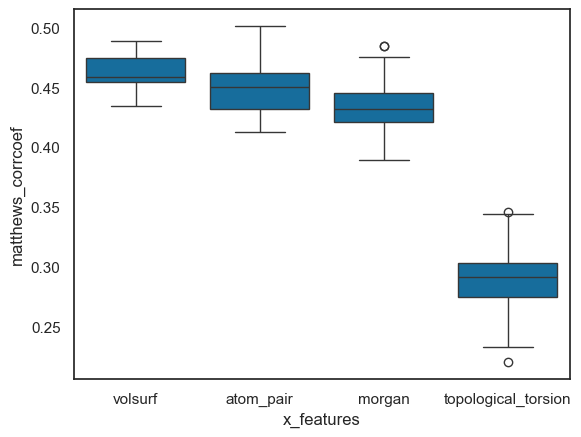

In [42]:
mean_order = (
    df_model_data_mean.groupby("x_features")["matthews_corrcoef"]
    .mean()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=df_model_data_mean,
    y="matthews_corrcoef",
    x="x_features",
    order=mean_order,
)

In [43]:
T = []
norm_pval = 0.05
for x in df_model_data_mean["x_features"].unique():
    df_x = df_model_data_mean[df_model_data_mean["x_features"] == x]
    x_ba = df_x["matthews_corrcoef"].values
    x_ba_shapiro_pvalue = ss.shapiro(x_ba).pvalue
    value = 0.05
    if x_ba_shapiro_pvalue < 0.05:
        operator = "<"
        norm_pval = x_ba_shapiro_pvalue
        if x_ba_shapiro_pvalue < 0.01:
            value = 0.01
            if x_ba_shapiro_pvalue < 0.001:
                value = 0.001
    else:
        operator = "≥"
    T.append(
        pd.DataFrame(
            {
                "X": [x],
                "test": ["shapiro_wilk"],
                "operator": [operator],
                "pvalue": [value],
            }
        )
    )
pd.concat(T, ignore_index=True)

,X,test,operator,pvalue
0,atom_pair,shapiro_wilk,≥,0.05
1,morgan,shapiro_wilk,≥,0.05
2,topological_torsion,shapiro_wilk,≥,0.05
3,volsurf,shapiro_wilk,≥,0.05


In [44]:
df_pivoted = df_model_data_mean.pivot_table(
    index=["model_id"],
    columns="x_features",
    values="matthews_corrcoef",
)

In [45]:
pairs = list(combinations(mean_order, 2))
ordered_pairs = []

current_pair = pairs[0]
ordered_pairs.append(current_pair)

for _ in range(1, len(pairs)):
    next_pair = next(
        (
            pair
            for pair in pairs
            if pair[0] == current_pair[1] and pair not in ordered_pairs
        ),
        None,
    )
    if next_pair:
        ordered_pairs.append(next_pair)
        current_pair = next_pair
    else:
        break

In [46]:
T = []
i = 0
for x1, x2 in ordered_pairs:
    if norm_pval < 0.05:
        test_name = "wilcoxon"
        posthoc_pvalue = ss.wilcoxon(
            x=df_pivoted[x1].values,
            y=df_pivoted[x2].values,
        ).pvalue
    else:
        test_name = "t-test"
        posthoc_pvalue = ss.ttest_rel(
            a=df_pivoted[x1].values,
            b=df_pivoted[x2].values,
        ).pvalue
    value = 0.05
    if posthoc_pvalue < 0.05:
        operator = "<"
        i = 1
        if posthoc_pvalue < 0.01:
            value = 0.01
            if posthoc_pvalue < 0.001:
                value = 0.001
    else:
        operator = "≥"
    T.append(
        pd.DataFrame(
            {
                "x1": [x1],
                "x2": [x2],
                "test": [test_name],
                "operator": [operator],
                "pvalue": [value],
            }
        )
    )
    i += 1
df_t = pd.concat(T, ignore_index=True)
df_t

,x1,x2,test,operator,pvalue
0,volsurf,atom_pair,t-test,<,0.010
1,atom_pair,morgan,t-test,<,0.010
2,morgan,topological_torsion,t-test,<,0.001


In [47]:
X = []
for index, row in df_t.iterrows():
    if row["pvalue"] >= 0.05:
        X.append(row["x1"])
        X.append(row["x2"])
    else:
        X.append(row["x1"])
        break
selected_x = list(dict.fromkeys(X))
selected_x

['volsurf']

# Model validation

In [48]:
filtered_df = df_model_data_mean[df_model_data_mean["x_features"].isin(selected_x)]

In [49]:
df_validation["volsurf"] = scaler.transform(df_validation[volsurf_cols]).tolist()

In [50]:
if RUN_VALID:
    R = []
    for index, row in tqdm(filtered_df.iterrows()):
        params = row[
            [
                "auto_class_weights",
                "max_depth",
                "n_estimators",
                "random_state",
                "verbose",
            ]
        ]
        model_params = {
            params.index[x]: params.values[x] for x in range(params.shape[0])
        }
        X_tr, X_te = (
            df_training[row["x_features"]].tolist(),
            df_validation[row["x_features"]].tolist(),
        )
        y_tr, y_te = df_training["y"].tolist(), df_validation["y"].tolist()
        model = CatBoostClassifier(**model_params)
        model.fit(X=X_tr, y=y_tr)
        y_pred = model.predict(X_te)
        recall = recall_score(
            y_te, y_pred, average=None, labels=CLASS_LABELS, zero_division=0
        )
        dict_results = {
            "model_id": row["model_id"],
            "x_features": row["x_features"],
            "balanced_accuracy_val": balanced_accuracy_score(y_te, y_pred),
            **{
                f"recall_class{label}_val": score
                for label, score in zip(CLASS_LABELS, recall)
            },
            "matthews_corrcoef_val": matthews_corrcoef(y_te, y_pred),
        }
        dict_results.update(model_params)
        R.append(pd.DataFrame(dict_results, index=[0]))
    df_results_val = pd.concat(R, ignore_index=True)
    df_results_val.to_csv(
        f"../results/tbl_{SPLITS}_{N_CLASSES}class_valid_results.csv",
        index=False,
    )
else:
    df_results_val = pd.read_csv(
        f"../results/tbl_{SPLITS}_{N_CLASSES}class_valid_results.csv"
    )

49it [02:10,  2.67s/it]


In [58]:
train_rename = {
    "balanced_accuracy": "balanced_accuracy_tra",
    **{column: f"{column}_tra" for column in RECALL_COLUMNS},
    "matthews_corrcoef": "matthews_corrcoef_tra",
}

df_merged = pd.merge(
    left=filtered_df.rename(columns=train_rename),
    right=df_results_val.drop(
        columns=[
            "auto_class_weights",
            "max_depth",
            "n_estimators",
            "random_state",
            "verbose",
        ]
    ),
    on=["x_features", "model_id"],
)

<Axes: xlabel='matthews_corrcoef_tra', ylabel='matthews_corrcoef_val'>

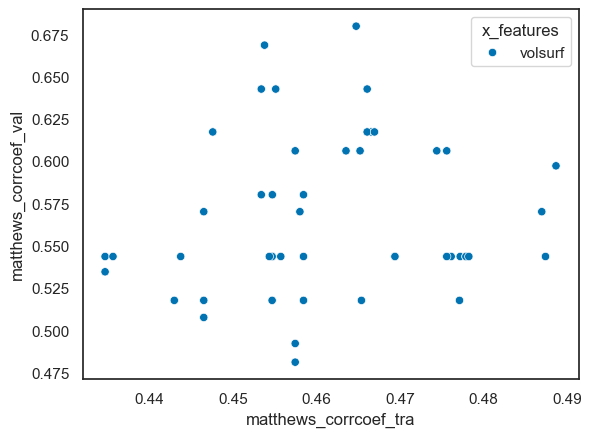

In [59]:
sns.scatterplot(
    df_merged, x="matthews_corrcoef_tra", y="matthews_corrcoef_val", hue="x_features"
)

In [60]:
df_merged["sum_col1_col2"] = (
    df_merged["matthews_corrcoef_tra"] * df_merged["matthews_corrcoef_val"]
)

result = df_merged.loc[df_merged["sum_col1_col2"].idxmax()]

result["x_features"]

'volsurf'

# Test set prediction

In [61]:
df_model = df_merged[
    (df_merged["model_id"] == result["model_id"])
    & (df_merged["x_features"] == result["x_features"])
]

In [62]:
df_training_val = dataset[dataset[splits_col] != "test"].copy()

In [63]:
df_training_val["volsurf"] = scaler.fit_transform(
    df_training_val[volsurf_cols]
).tolist()
df_test["volsurf"] = scaler.transform(df_test[volsurf_cols]).tolist()

In [64]:
if RUN_TEST:
    params = df_model[
        ["auto_class_weights", "max_depth", "n_estimators", "random_state", "verbose"]
    ]
    X_tr, X_te = (
        df_training_val[result["x_features"]].tolist(),
        df_test[result["x_features"]].tolist(),
    )
    y_tr, y_te = df_training_val["y"].tolist(), df_test["y"].tolist()
    model = CatBoostClassifier(**params.to_dict(orient="records")[0])
    model.fit(X=X_tr, y=y_tr)
    y_pred = model.predict(X_te)
    df_test["y_pred"] = y_pred
    recall = recall_score(
        y_te, y_pred, average=None, labels=CLASS_LABELS, zero_division=0
    )
    dict_results = {
        "x_features": result["x_features"],
        "balanced_accuracy_tes": balanced_accuracy_score(y_te, y_pred),
        **{
            f"recall_class{label}_tes": score
            for label, score in zip(CLASS_LABELS, recall)
        },
        "matthews_corrcoef_tes": matthews_corrcoef(y_te, y_pred),
    }
    dict_results.update(params.to_dict(orient="records")[0])
    df_results_tes = pd.DataFrame(dict_results, index=[0])
    df_results_tes.to_csv(
        f"../results/tbl_{SPLITS}_{N_CLASSES}class_test_results.csv",
        index=False,
    )
    df_test[["inchikey", "y_pred"]].to_csv(
        f"../results/tbl_{SPLITS}_{N_CLASSES}class_test_predictions.csv",
        index=False,
    )
else:
    df_results_tes = pd.read_csv(
        f"../results/tbl_{SPLITS}_{N_CLASSES}class_test_results.csv"
    )
    df_test = pd.merge(
        df_test,
        pd.read_csv(f"../results/tbl_{SPLITS}_{N_CLASSES}class_test_predictions.csv"),
        on="inchikey",
    )

In [65]:
print(
    classification_report(df_test["y"].tolist(), df_test["y_pred"].tolist(), digits=2)
)

              precision    recall  f1-score   support

           0       0.72      0.89      0.80        38
           1       0.78      0.52      0.62        27

    accuracy                           0.74        65
   macro avg       0.75      0.71      0.71        65
weighted avg       0.75      0.74      0.73        65



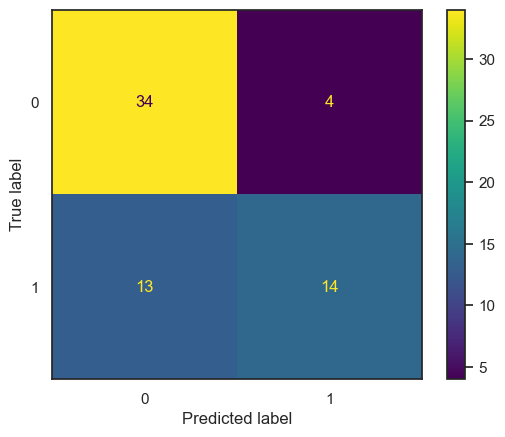

In [66]:
cm = confusion_matrix(
    y_true=df_test["y"].tolist(),
    y_pred=df_test["y_pred"].tolist(),
    labels=CLASS_LABELS,
)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_LABELS)
disp.plot()

# Domain of applicability

In [67]:
knn = NearestNeighbors(n_neighbors=5, n_jobs=-1, p=2)
X = df_training_val[volsurf_cols].values.tolist()
# X = df_training_val["morgan"].tolist()
knn.fit(X)
con_nbrs = knn.kneighbors(X, return_distance=True, n_neighbors=6)
D = np.mean([np.mean(n[1:]) for n in con_nbrs[0]])
std = np.std([np.mean(n[1:]) for n in con_nbrs[0]])
doa_threshold = D + std * 0.5

In [68]:
# samples = df_test["morgan"].tolist()
samples = df_test[volsurf_cols].values.tolist()
samples_nbrs = knn.kneighbors(samples, return_distance=True, n_neighbors=5)
df_test["mean_distance"] = [np.mean(n) for n in samples_nbrs[0]]
df_test.loc[
    df_test["mean_distance"] <= doa_threshold,
    "in_domain",
] = "yes"
df_test.loc[
    df_test["mean_distance"] > doa_threshold,
    "in_domain",
] = "no"

In [69]:
df_test["in_domain"].value_counts()

in_domain
yes    60
no      5
Name: count, dtype: int64

In [70]:
df_results_tes

,x_features,balanced_accuracy_tes,recall_class0_tes,recall_class1_tes,matthews_corrcoef_tes,auto_class_weights,max_depth,n_estimators,random_state,verbose
0,volsurf,0.706628,0.894737,0.518519,0.4551,Balanced,4,400,0,False


In [71]:
y_e = df_test[df_test["in_domain"] == "yes"]["y"]
y_p = df_test[df_test["in_domain"] == "yes"]["y_pred"]
recall = recall_score(y_e, y_p, average=None, labels=CLASS_LABELS, zero_division=0)
dict_results = {
    "balanced_accuracy": balanced_accuracy_score(y_e, y_p),
    **{f"recall_class{label}": score for label, score in zip(CLASS_LABELS, recall)},
    "matthews_corrcoef": matthews_corrcoef(y_e, y_p),
}
pd.DataFrame(dict_results, index=[0]).round(2)

,balanced_accuracy,recall_class0,recall_class1,matthews_corrcoef
0,0.71,0.91,0.5,0.46


In [72]:
round(len(df_test[df_test["in_domain"] == "no"]) / len(df_test), 2)

0.08

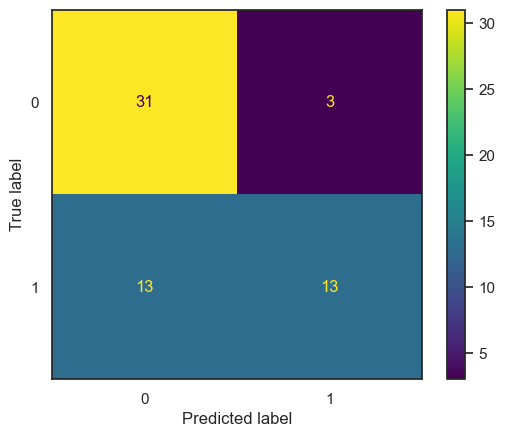

In [73]:
cm = confusion_matrix(
    y_true=y_e,
    y_pred=y_p,
    labels=CLASS_LABELS,
)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_LABELS)
disp.plot()

# UMAP

In [74]:
morgan_umap = UMAP(
    metric="manhattan",
    random_state=0,
)

df_umap = dataset.copy()
X_umap = morgan_umap.fit_transform(df_umap["morgan"].tolist())

umap_cols = ["morgan_umap%s" % (i + 1) for i in range(len(X_umap[0]))]

df_umap[umap_cols] = pd.DataFrame(
    {"UMAP%s" % i: X_umap[:, i] for i in range(len(X_umap[0]))},
    index=df_umap.index,
)

/opt/homebrew/Caskroom/miniconda/base/envs/dili_models/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<Axes: xlabel='morgan_umap1', ylabel='morgan_umap2'>

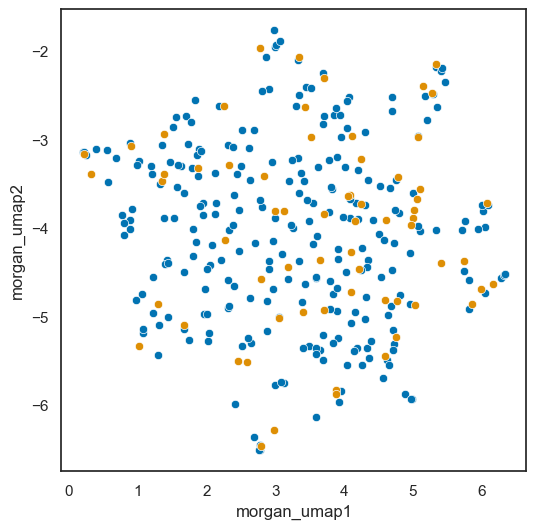

In [75]:
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    data=df_umap[df_umap[splits_col] != "test"],
    x="morgan_umap1",
    y="morgan_umap2",
    ax=ax,
)
sns.scatterplot(
    data=df_umap[df_umap[splits_col] == "test"],
    x="morgan_umap1",
    y="morgan_umap2",
    ax=ax,
)

In [76]:
X_fit = df_umap[df_umap[splits_col] != "test"][umap_cols]
X_predict = df_umap[df_umap[splits_col] == "test"][umap_cols]

df_dist = pd.DataFrame(
    {
        "X": umap_cols,
        "distances": list(
            map(
                lambda i: ss.ks_2samp(X_fit.iloc[:, i], X_predict.iloc[:, i]).pvalue,
                range(X_fit.shape[1]),
            )
        ),
    }
)

df_dist["distances"].mean().round(2)

0.5

### <span style="color:black"> <b><center> End of the notebook </span></b></center> <a id='test_configuration_file'></a>
***
!-- [Back to Index](#Index) -->